In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../data/raw/Sample-Superstore.csv",encoding="cp1252")

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

**Date**
Tipe data kolom "Ship date" dan "Order Date" berupa object, harus diganti menjadi date time 

In [3]:
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

**Menghitung Jumlah Pesanan**

In [5]:
# Menghitung jumlah seluruh baris transaksi
total_rows = len(df)

# Menghitung jumlah pesanan unik
total_orders = df['Order ID'].nunique()

print("Total Rows:", total_rows)
print("Total Orders:", total_orders)

Total Rows: 9994
Total Orders: 5009


**Mengecek apakah ada data terduplikat tanpa adanya Row ID**

In [6]:
# Menghitung duplikat tanpa Row ID
duplicate_count = df.drop(columns=['Row ID']).duplicated().sum()

print("Duplicate Rows:", duplicate_count)

Duplicate Rows: 1


In [7]:
duplicates = df[df.drop(columns=['Row ID']).duplicated(keep=False)].sort_values('Order ID')

duplicates

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
3405,3406,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
3406,3407,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588


In [8]:
df_clean = df.drop_duplicates(
    subset=df.columns.drop('Row ID'),
    keep='first'
).copy()

print("Rows before:", len(df))
print("Rows after:", len(df_clean))

Rows before: 9994
Rows after: 9993


*Kesimpulan: Dataset berisi 9.994 baris, tetapi hanya 5.009 Order ID unik. Artinya satu baris mewakili satu item produk dalam sebuah pesanan, bukan satu pesanan utuh. Karena itu jumlah pesanan dihitung dari Order ID unik, bukan dari jumlah baris.*

**Memperbaiki tipe dari Postal Code yang berupa int menjadi string**

dikarenakan kode pos bukan angka untuk perhitungan, jadi lebih baik menyimpannya menjadi string

In [9]:
df_clean['Postal Code'] = (df_clean['Postal Code'].astype(str).str.zfill(5))

In [10]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9993 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9993 non-null   int64         
 1   Order ID       9993 non-null   object        
 2   Order Date     9993 non-null   datetime64[ns]
 3   Ship Date      9993 non-null   datetime64[ns]
 4   Ship Mode      9993 non-null   object        
 5   Customer ID    9993 non-null   object        
 6   Customer Name  9993 non-null   object        
 7   Segment        9993 non-null   object        
 8   Country        9993 non-null   object        
 9   City           9993 non-null   object        
 10  State          9993 non-null   object        
 11  Postal Code    9993 non-null   object        
 12  Region         9993 non-null   object        
 13  Product ID     9993 non-null   object        
 14  Category       9993 non-null   object        
 15  Sub-Category   9993 non-nu

**Menghitung Konsistensi Tanggal & Shipping Duration**

In [11]:
invalid_dates = df_clean[df_clean['Ship Date']< df_clean["Order Date"]]

print("invalid_dates", len(invalid_dates))

invalid_dates 0


In [12]:
df_clean['Shipping Duration']= (df_clean['Ship Date']- df_clean['Order Date']).dt.days

In [13]:
df_clean[['Ship Date','Order Date','Shipping Duration']].head(5)

,Ship Date,Order Date,Shipping Duration
0,2016-11-11,2016-11-08,3
1,2016-11-11,2016-11-08,3
2,2016-06-16,2016-06-12,4
3,2015-10-18,2015-10-11,7
4,2015-10-18,2015-10-11,7


In [14]:
df_clean['Shipping Duration'].describe()

count    9993.000000
mean        3.958171
std         1.747654
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping Duration, dtype: float64

*Kesimpulan: Tidak ada Ship Date yang lebih awal dari Order Date. Durasi pengiriman rata-rata 4, minimum 0 hari (dikirim di hari yang sama), dan maksimum 7 hari.*

**Mengecek Konsistensi penulisan Customer dan Product**

In [15]:
print(df_clean['Customer Name'].nunique())
customer_check = (
    df_clean.assign(
        normalized=df_clean['Customer Name']
        .str.strip()
        .str.lower()
    )
    .groupby('normalized')['Customer Name']
    .nunique()
)

customer_duplicates = customer_check[
    customer_check > 1
]

print(customer_duplicates)

793
Series([], Name: Customer Name, dtype: int64)


In [16]:
df_clean.groupby('Customer ID')[
    'Customer Name'
].nunique().loc[lambda x: x > 1]

Series([], Name: Customer Name, dtype: int64)

In [17]:
product_check = (
    df_clean.assign(
        normalized=df_clean['Product Name']
        .str.strip()
        .str.lower()
    )
    .groupby('normalized')['Product Name']
    .nunique()
)

product_duplicates = product_check[
    product_check > 1
]

print(product_duplicates)

Series([], Name: Product Name, dtype: int64)


**Pemeriksaan Product ID dan Product Name**

In [18]:
# Satu Product ID dengan lebih dari satu Product Name
id_to_names = df_clean.groupby('Product ID')['Product Name'].nunique()
product_id_inconsistent = id_to_names[id_to_names > 1]
print('Jumlah Product ID dengan banyak nama:', len(product_id_inconsistent))

# Satu Product Name dengan lebih dari satu Product ID
name_to_ids = df_clean.groupby('Product Name')['Product ID'].nunique()
product_name_multiple_ids = name_to_ids[name_to_ids > 1]
print('Jumlah Product Name dengan banyak ID:', len(product_name_multiple_ids))

Jumlah Product ID dengan banyak nama: 32
Jumlah Product Name dengan banyak ID: 16


*Catatan/keputusan: ditemukan 32 Product ID yang terhubung ke lebih dari satu Product Name, dan 16 Product Name yang memiliki lebih dari satu Product ID.*

In [19]:
contoh_id = product_id_inconsistent.index[:5]
(df_clean[df_clean['Product ID'].isin(contoh_id)]
    [['Product ID', 'Product Name']].drop_duplicates().sort_values(['Product ID', 'Product Name']))

,Product ID,Product Name
2115,FUR-BO-10002213,DMI Eclipse Executive Suite Bookcases
2471,FUR-BO-10002213,"Sauder Forest Hills Library, Woodland Oak Finish"
128,FUR-CH-10001146,"Global Task Chair, Black"
66,FUR-CH-10001146,"Global Value Mid-Back Manager's Chair, Gray"
1459,FUR-FU-10001473,DAX Wood Document Frame
2204,FUR-FU-10001473,"Eldon Executive Woodline II Desk Accessories, ..."
3831,FUR-FU-10004017,"Executive Impressions 13"" Chairman Wall Clock"
234,FUR-FU-10004017,Tenex Contemporary Contur Chairmats for Low an...
1385,FUR-FU-10004091,"Eldon 200 Class Desk Accessories, Black"
293,FUR-FU-10004091,"Howard Miller 13"" Diameter Goldtone Round Wall..."


In [20]:
contoh_nama = product_name_multiple_ids.index[:5]
(df_clean[df_clean['Product Name'].isin(contoh_nama)]
    [['Product Name', 'Product ID']].drop_duplicates().sort_values(['Product Name', 'Product ID']))

,Product Name,Product ID
985,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",OFF-EN-10000461
1989,"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",OFF-EN-10000781
2531,Avery Non-Stick Binders,OFF-BI-10000829
336,Avery Non-Stick Binders,OFF-BI-10004140
34,Easy-staple paper,OFF-PA-10000249
1080,Easy-staple paper,OFF-PA-10000349
283,Easy-staple paper,OFF-PA-10000474
4360,Easy-staple paper,OFF-PA-10000565
1225,Easy-staple paper,OFF-PA-10001685
4999,Easy-staple paper,OFF-PA-10002764


**Mendeteksi Outlier**

In [21]:
Q1 = df_clean['Profit'].quantile(0.25)
Q3 = df_clean['Profit'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 1.731
Q3: 29.364
IQR: 27.633
Lower Bound: -39.7185
Upper Bound: 70.8135


In [22]:
profit_outliers = df_clean[
    (df_clean['Profit'] < lower_bound) |
    (df_clean['Profit'] > upper_bound)
]

print("Total Profit Outliers:", len(profit_outliers))

Total Profit Outliers: 1881


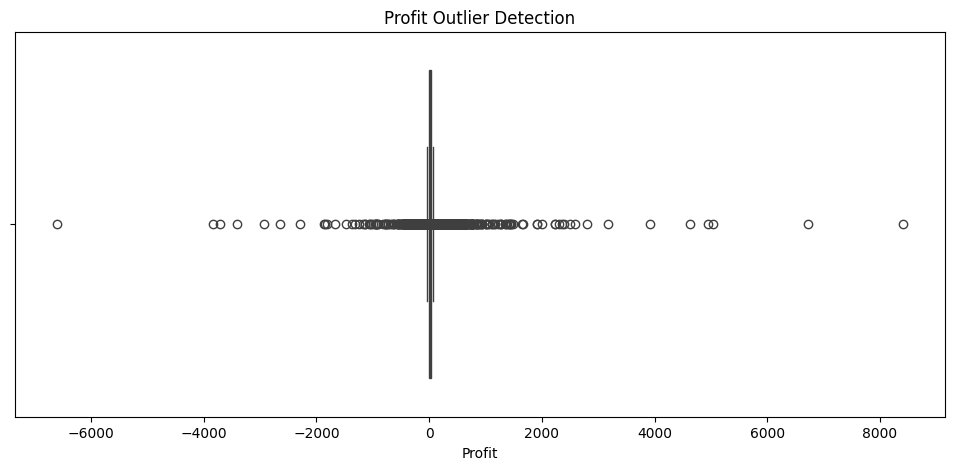

In [23]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df_clean['Profit'])

plt.title('Profit Outlier Detection')
plt.xlabel('Profit')
plt.show()

**Pemeriksaan nilai unik kolom kategorikal**

In [24]:
kolom_kategorikal = ['City', 'State', 'Sub-Category', 'Segment', 'Ship Mode', 'Region']

for col in kolom_kategorikal:
    nilai = df_clean[col]
    n_unik = nilai.nunique()
    n_spasi = (nilai != nilai.str.strip()).sum()
    n_unik_normal = nilai.str.strip().str.lower().nunique()

    print(f'\n{col}: {n_unik} nilai unik | spasi di awal/akhir: {n_spasi} | variasi huruf: {n_unik - n_unik_normal}')
    if n_unik <= 50:
        print(sorted(nilai.unique()))


City: 531 nilai unik | spasi di awal/akhir: 0 | variasi huruf: 0

State: 49 nilai unik | spasi di awal/akhir: 0 | variasi huruf: 0
['Alabama', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming']

Sub-Category: 17 nilai unik | spasi di awal/akhir: 0 | variasi huruf: 0
['Accessories', 'Appliances', 'Art', 'Binders', 'Bookcases', 'Chairs', 'Copiers', 'Envelopes', 'Fasteners', 'Furnishings', 'Labels', 'Machines', 'Paper', 'Phones', 'Sto

*Catatan: pemeriksaan nilai unik menunjukkan tidak ada spasi di awal/akhir pada keenam kolom kategorikal. Nilai unik yang tampil juga tidak memperlihatkan variasi ejaan ganda yang jelas. City dan State memiliki banyak nilai karena merupakan wilayah geografis, bukan karena duplikasi penulisan.*

**Meninjau 10 profit terendah dan tertinggi**

In [25]:
cols = ['Product Name', 'Category', 'Sub-Category', 'Discount', 'Sales', 'Quantity', 'Profit']
print('10 Profit Terendah:')
display(df_clean.nsmallest(10, 'Profit')[cols])
print('10 Profit Tertinggi:')
display(df_clean.nlargest(10, 'Profit')[cols])


10 Profit Terendah:


,Product Name,Category,Sub-Category,Discount,Sales,Quantity,Profit
7772,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,0.7,4499.985,5,-6599.9780
683,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,0.5,7999.980,4,-3839.9904
9774,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,0.8,2177.584,8,-3701.8928
3011,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,0.7,2549.985,5,-3399.9800
4991,Ibico EPK-21 Electric Binding System,Office Supplies,Binders,0.8,1889.990,5,-2929.4845
3151,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,0.7,1799.994,2,-2639.9912
5310,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,0.8,1525.188,6,-2287.7820
9639,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,0.4,4297.644,13,-1862.3124
1199,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,0.8,1088.792,4,-1850.9464
2697,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,0.5,22638.480,6,-1811.0784


10 Profit Tertinggi:


,Product Name,Category,Sub-Category,Discount,Sales,Quantity,Profit
6826,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,0.0,17499.950,5,8399.9760
8153,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,0.0,13999.960,4,6719.9808
4190,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,0.0,10499.970,3,5039.9856
9039,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Binders,0.0,9892.740,13,4946.3700
4098,Ibico EPK-21 Electric Binding System,Office Supplies,Binders,0.0,9449.950,5,4630.4755
2623,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,0.2,11199.968,4,3919.9888
509,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,0.0,6354.950,5,3177.4750
8488,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,0.0,8749.950,5,2799.9840
7666,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,0.0,5399.910,9,2591.9568
6520,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,0.0,5443.960,4,2504.2216


*Catatan pola dan keputusan outlier: Pada 10 profit terendah, diskon umumnya tinggi (sekitar 0,4–0,8), terutama pada produk kategori Technology (Machines) dan Office Supplies (Binders). Sebaliknya, 10 profit tertinggi didominasi transaksi tanpa diskon (0,0), dengan beberapa transaksi diskon 0,2; produk Technology (Copiers) dan Office Supplies (Binders) terlihat menonjol. Pola ini mengindikasikan bahwa diskon tinggi berkaitan dengan risiko profit negatif pada sebagian transaksi, meskipun belum membuktikan hubungan sebab-akibat.*

*Keputusan: outlier Profit dipertahankan, tidak dihapus. Metode IQR menandai 1.881 baris (sekitar 18,8% atau ±19% data). Jumlah tersebut cukup besar dan nilai ekstrem dapat merepresentasikan transaksi bisnis yang benar-benar terjadi, terutama transaksi dengan diskon tinggi atau nilai penjualan besar. Menghapus semuanya berisiko menghilangkan informasi penting. Outlier akan dipertahankan dan dianalisis lebih lanjut, khususnya berdasarkan Discount, Category, dan Sub-Category.*

**Menghapus Row ID dan Country**

In [26]:
df_clean = df_clean.drop(columns=['Row ID', 'Country'], errors='ignore').copy()

In [27]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9993 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order ID           9993 non-null   object        
 1   Order Date         9993 non-null   datetime64[ns]
 2   Ship Date          9993 non-null   datetime64[ns]
 3   Ship Mode          9993 non-null   object        
 4   Customer ID        9993 non-null   object        
 5   Customer Name      9993 non-null   object        
 6   Segment            9993 non-null   object        
 7   City               9993 non-null   object        
 8   State              9993 non-null   object        
 9   Postal Code        9993 non-null   object        
 10  Region             9993 non-null   object        
 11  Product ID         9993 non-null   object        
 12  Category           9993 non-null   object        
 13  Sub-Category       9993 non-null   object        
 14  Product Name 

In [28]:
df_clean.columns = (
    df_clean.columns
    .str.lower()
    .str.replace(r'[\s-]+', '_', regex=True)
)

In [29]:
df_clean = df_clean.reset_index(drop=True)   # indeks kembali rapi 0..9992
print(df_clean.columns.tolist())             # cek: tidak ada '_ale_' dan sejenisnya

# verifikasi kode pos
print(df_clean['postal_code'].str.len().value_counts())                       # harus semua 5
print(df_clean[df_clean['postal_code'].str.startswith('0')]['state'].unique())  # state timur laut AS?

['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_duration']
postal_code
5    9993
Name: count, dtype: int64
['Connecticut' 'New Jersey' 'Massachusetts' 'Rhode Island' 'New Hampshire'
 'Vermont' 'Maine']


In [30]:
from pathlib import Path
output_dir = Path('../data/cleaned')
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / 'Sample-Superstore-Cleaned.csv'

df_clean.to_csv(output_path, index=False)
print('Data bersih disimpan ke:', output_path)

Data bersih disimpan ke: ..\data\cleaned\Sample-Superstore-Cleaned.csv


In [31]:
check = pd.read_csv(output_path,
                    dtype={'postal_code': str},
                    parse_dates=['order_date', 'ship_date'])
print(check.shape)        # harus (9993, 20)
print(check.columns.tolist())
check.info()

(9993, 20)
['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_duration']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9993 entries, 0 to 9992
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   order_id           9993 non-null   object        
 1   order_date         9993 non-null   datetime64[ns]
 2   ship_date          9993 non-null   datetime64[ns]
 3   ship_mode          9993 non-null   object        
 4   customer_id        9993 non-null   object        
 5   customer_name      9993 non-null   object        
 6   segment            9993 non-null   object        
 7   city               9993 non-null   object        
 8   state              9993 non-null   object        
 9   postal_code 